In [1]:
import cv2
import numpy as np
from matplotlib import pyplot as plt

# Question 1

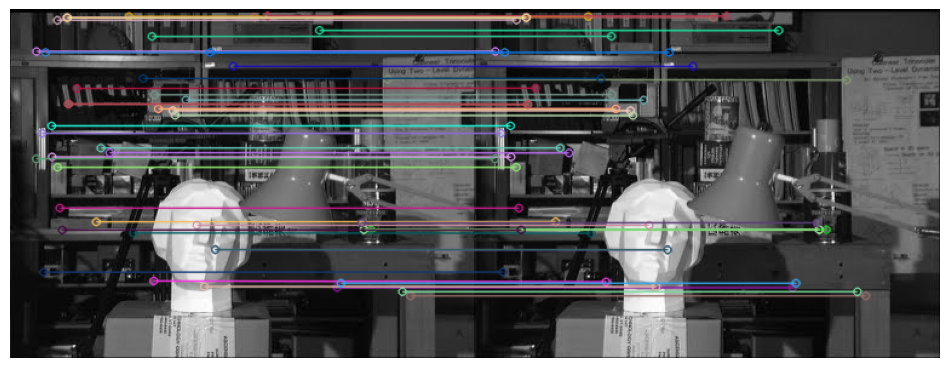

In [2]:
image1 = cv2.imread('./imgs/Q1-Left.jpg', 0)
image2 = cv2.imread('./imgs/Q1-Right.jpg', 0)

sift = cv2.SIFT_create()

keypoint1, desc1 = sift.detectAndCompute(image1, None)
keypoint2, desc2 = sift.detectAndCompute(image2, None)

brute_force_matcher = cv2.BFMatcher(cv2.NORM_L2, crossCheck=True)
matches = brute_force_matcher.match(desc1, desc2)

matches = sorted(matches, key=lambda x: x.distance)

top_matches = matches[:50]

pts1 = np.float32([keypoint1[m.queryIdx].pt for m in top_matches])
pts2 = np.float32([keypoint2[m.trainIdx].pt for m in top_matches])

matched_img = cv2.drawMatches(image1, keypoint1, image2, keypoint2, top_matches, None, flags=cv2.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS)

plt.figure(figsize=(12, 6))
plt.imshow(matched_img)
plt.axis('off')
plt.show()

In [3]:
F, mask = cv2.findFundamentalMat(pts1, pts2, cv2.FM_RANSAC, confidence=0.99, ransacReprojThreshold=1)
F

array([[ 1.22176515e-06, -9.07111470e-04,  1.77384958e-01],
       [ 9.17629496e-04, -1.65480211e-05,  6.99079151e-01],
       [-1.78849837e-01, -7.02346914e-01,  1.00000000e+00]])

In [4]:
P1 = np.hstack((np.eye(3), np.zeros((3, 1))))

_, _, Vt = np.linalg.svd(F.T)
e2 = Vt[-1]
e2 = e2 / e2[2]

def skew(x):
    return np.array([
        [0, -x[2], x[1]],
        [x[2], 0, -x[0]],
        [-x[1], x[0], 0]
    ])

P2 = np.hstack((skew(e2) @ F, e2.reshape(3, 1)))
P2

array([[-3.50447260e+01, -1.37617725e+02,  1.95240761e+02,
        -7.77841924e+02],
       [-1.39116900e+02, -5.46315782e+02,  7.78019309e+02,
         1.95939840e+02],
       [-7.14010085e-01,  1.90611021e-01, -5.78529852e+02,
         1.00000000e+00]])

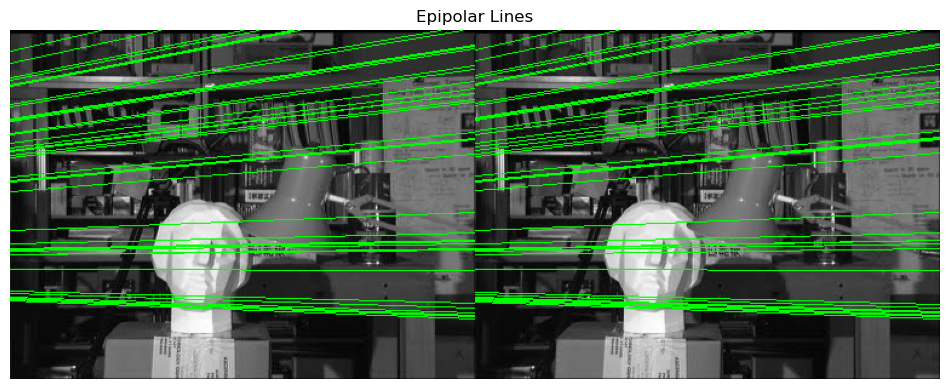

In [5]:
#inlier points F matrix
pts1_inlier = pts1[mask.ravel() == 1]
pts2_inlier = pts2[mask.ravel() == 1]

lines1 = cv2.computeCorrespondEpilines(pts2_inlier.reshape(-1, 1, 2), 2, F)
lines1 = lines1.reshape(-1, 3)

lines2 = cv2.computeCorrespondEpilines(pts1_inlier.reshape(-1, 1, 2), 1, F)
lines2 = lines2.reshape(-1, 3)

def draw_lines_on(img, lines, color):
        h, w = img.shape[:2]
        for a, b, c in lines:
            #compute two points on the line:  x=0 and x=w
            if abs(b) > 1e-6:          #avoid division by zero
                y0 = int(-c / b)
                y1 = int(-(a * w + c) / b)
                cv2.line(img, (0, y0), (w, y1), color, 1)
            else:
                #vertical line: x = -c/a
                x = int(-c / a)
                cv2.line(img, (x, 0), (x, h), color, 1)

img1_lines = cv2.cvtColor(image1.copy(), cv2.COLOR_GRAY2BGR)
img2_lines = cv2.cvtColor(image2.copy(), cv2.COLOR_GRAY2BGR)
draw_lines_on(img1_lines, lines1, (0, 255, 0))
draw_lines_on(img2_lines, lines2, (0, 255, 0))

combined = np.hstack((img1_lines, img2_lines))
plt.figure(figsize=(12, 6))
plt.imshow(combined[..., ::-1])
plt.title('Epipolar Lines')
plt.axis('off')
plt.show()

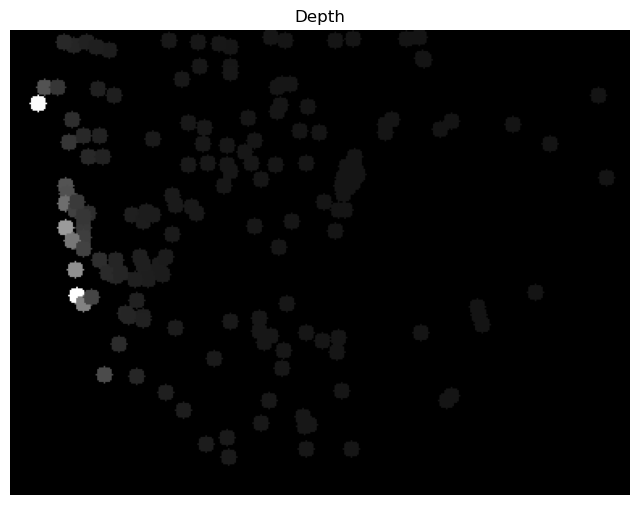

In [6]:
image1 = cv2.imread('./imgs/Q1-Left.jpg', 0)
image2 = cv2.imread('./imgs/Q1-Right.jpg', 0)

sift = cv2.SIFT_create()
keypoint1, desc1 = sift.detectAndCompute(image1, None)
keypoint2, desc2 = sift.detectAndCompute(image2, None)

brute_force_matcher = cv2.BFMatcher(cv2.NORM_L2, crossCheck=True)
matches = brute_force_matcher.match(desc1, desc2)
matches = sorted(matches, key=lambda x: x.distance)
top_matches = matches[:220]

pts1 = np.float32([keypoint1[m.queryIdx].pt for m in top_matches])
pts2 = np.float32([keypoint2[m.trainIdx].pt for m in top_matches])

F, mask = cv2.findFundamentalMat(pts1, pts2, cv2.FM_RANSAC, 
                                 ransacReprojThreshold=1, confidence=0.99)
pts1_inlier = pts1[mask.ravel()==1]
pts2_inlier = pts2[mask.ravel()==1]

P1 = np.hstack([np.eye(3), np.zeros((3,1))])

_, _, Vt = np.linalg.svd(F.T)
e2 = Vt[-1]
e2 /= e2[2]

def skew(x):
    return np.array([[0,-x[2],x[1]], [x[2],0,-x[0]], [-x[1],x[0],0]])

P2 = np.hstack([skew(e2) @ F, e2.reshape(3,1)])

pts1_h = pts1_inlier.T.astype(float)
pts2_h = pts2_inlier.T.astype(float)

points_4D = cv2.triangulatePoints(P1, P2, pts1_h, pts2_h)
points_3D = (points_4D[:3] / points_4D[3]).T
depth_vals = points_3D[:, 2]

mask_valid = (depth_vals > 0)
depth_vals = depth_vals[mask_valid]
pts_filtered = pts1_inlier[mask_valid]

lower, upper = np.percentile(depth_vals, [1, 99])
mask_percentile = (depth_vals >= lower) & (depth_vals <= upper)
depth_filtered = depth_vals[mask_percentile]
pts_filtered = pts_filtered[mask_percentile]

depth_norm = cv2.normalize(depth_filtered, None, 0, 255, cv2.NORM_MINMAX).astype(np.uint8)

#output_img = cv2.cvtColor(image1.copy(), cv2.COLOR_GRAY2BGR)
output_img = cv2.cvtColor(np.zeros_like(image1), cv2.COLOR_GRAY2BGR)

xs = np.round(pts_filtered[:, 0]).astype(int)
ys = np.round(pts_filtered[:, 1]).astype(int)

for x, y, v in zip(xs, ys, depth_norm):
    gray_val = int(v.item()) + 20
    if 0 <= x < output_img.shape[1] and 0 <= y < output_img.shape[0]:
        cv2.circle(output_img, (x, y), radius=5, color=(gray_val,gray_val,gray_val), thickness=-1)

plt.figure(figsize=(8, 8))
plt.imshow(cv2.cvtColor(output_img, cv2.COLOR_BGR2RGB))
plt.axis('off')
plt.title("Depth")
plt.show()

# Question 2

In [7]:
img = cv2.imread('./imgs/image2.jpg', cv2.IMREAD_REDUCED_COLOR_4)
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

square_size = 2.65 #cm
pattern_size = (7, 5)

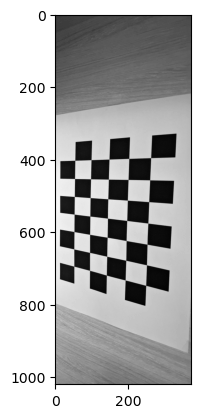

In [8]:
plt.imshow(gray[:, 390:], cmap='gray')

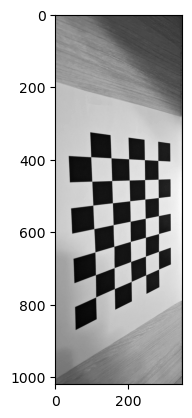

In [9]:
plt.imshow(gray[:, 20:370], cmap='gray')

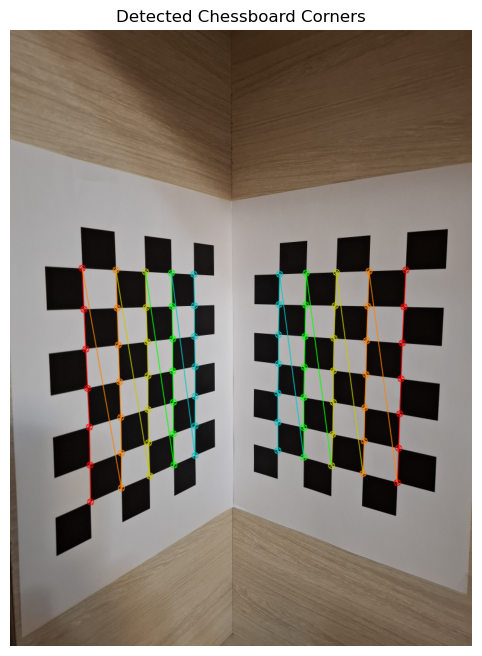

In [10]:
roi_plane1 = gray[:, 20:370]
roi_plane2 = gray[:, 390:]

objpoints = []  #3D points in real world
imgpoints = []  #2D points in image

#plane 1
ret1, corners1 = cv2.findChessboardCorners(roi_plane1, pattern_size, None)
corners1 = cv2.cornerSubPix(roi_plane1, corners1, (11,11), (-1,-1), (cv2.TERM_CRITERIA_EPS + cv2.TERM_CRITERIA_MAX_ITER, 30, 0.001))

corners1[:,0,0] += 20 #x offset
corners1[:,0,1] += 0  #y offset

imgpoints.append(corners1)

#3D object points for plane 1 (z=0)
objp1 = np.zeros((pattern_size[0]*pattern_size[1], 3), np.float32)
objp1[:, :2] = np.mgrid[0:pattern_size[0], 0:pattern_size[1]].T.reshape(-1,2)
objp1 *= square_size
objpoints.append(objp1)

cv2.drawChessboardCorners(img, pattern_size, corners1, ret1)

#plane 2
ret2, corners2 = cv2.findChessboardCorners(roi_plane2, pattern_size, None)
corners2 = cv2.cornerSubPix(roi_plane2, corners2, (11,11), (-1,-1), (cv2.TERM_CRITERIA_EPS + cv2.TERM_CRITERIA_MAX_ITER, 30, 0.001))

corners2[:,0,0] += 390 #x offset
corners2[:,0,1] += 0   #y offset

imgpoints.append(corners2)

#3D object points for plane 2 (x=0)
objp2 = np.zeros((pattern_size[0]*pattern_size[1], 3), np.float32)
objp2[:, [1,2]] = np.mgrid[0:pattern_size[0], 0:pattern_size[1]].T.reshape(-1,2)
objp2 *= square_size
objpoints.append(objp2)

cv2.drawChessboardCorners(img, pattern_size, corners2, ret2)

plt.figure(figsize=(8,8))
plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
plt.title('Detected Chessboard Corners')
plt.axis('off')
plt.show()

In [11]:
h, w = gray.shape[:2]

K_init = np.array([
    [w, 0, w / 2],
    [0, w, h / 2],
    [0, 0, 1]
], dtype=np.float64)

dist_init = np.zeros((5, 1)) #assume no distortion initially

ret, K, dist, rvecs, tvecs = cv2.calibrateCamera(objpoints, imgpoints, gray.shape[::-1], K_init, dist_init, flags=cv2.CALIB_USE_INTRINSIC_GUESS)


print('Reprojection RMS error:')
print(ret)

print('\nCamera intrinsic matrix K:')
print(K)

print('\nDistortion coefficients:')
print(dist)

print('\nRotations:')
print(rvecs)

print('\nTranslations:')
print(tvecs)

Reprojection RMS error:
0.36266498516886236

Camera intrinsic matrix K:
[[742.91303001   0.         385.23416005]
 [  0.         730.20783341 522.41012748]
 [  0.           0.           1.        ]]

Distortion coefficients:
[[ 3.56079768e-01]
 [-1.99594461e+00]
 [ 4.53707779e-03]
 [ 3.04904086e-03]
 [ 4.14715887e+00]]

Rotations:
(array([[ 0.83355333],
       [-0.65673121],
       [-1.49326474]]), array([[ 0.11246592],
       [-0.90768575],
       [-0.05371289]]))

Translations:
(array([[-10.32062484],
       [ 10.72743595],
       [ 31.21437156]]), array([[11.47853616],
       [-5.46696709],
       [32.42040322]]))


In [12]:
R1, _ = cv2.Rodrigues(rvecs[0])
R2, _ = cv2.Rodrigues(rvecs[1])

t1 = tvecs[0]
t2 = tvecs[1]

Rt1 = np.hstack((R1, t1))
Rt2 = np.hstack((R2, t2))

print('[R|t]1:')
print(Rt1)
print('\n[R|t]2:')
print(Rt2)

[R|t]1:
[[ 2.31964968e-03  5.82268776e-01 -8.12993045e-01 -1.03206248e+01]
 [-9.92733154e-01 -9.64742705e-02 -7.19277352e-02  1.07274359e+01]
 [-1.20314185e-01  8.07251998e-01  5.77813732e-01  3.12143716e+01]]

[R|t]2:
[[ 6.14731145e-01 -1.06240373e-03 -7.88736008e-01  1.14785362e+01]
 [-9.40771646e-02  9.92761502e-01 -7.46598052e-02 -5.46696709e+00]
 [ 7.83106063e-01  1.20097755e-01  6.10181468e-01  3.24204032e+01]]


In [13]:
P1 = K @ Rt1
P2 = K @ Rt2

print("Projection matrix P1:\n", P1)
print("Projection matrix P2:\n", P2)

Projection matrix P1:
 [[-4.46258361e+01  7.43556106e+02 -3.81389539e+02  4.35751554e+03]
 [-7.87754875e+02  3.51270351e+02  2.49333550e+02  2.41399616e+04]
 [-1.20314185e-01  8.07251998e-01  5.77813732e-01  3.12143716e+01]]
Projection matrix P2:
 [[ 7.58370984e+02  4.54764841e+01 -3.50899512e+02  2.10170009e+04]
 [ 3.40406656e+02  7.87662509e+02  2.64247804e+02  1.29447248e+04]
 [ 7.83106063e-01  1.20097755e-01  6.10181468e-01  3.24204032e+01]]


In [14]:
total_error = 0

for i in range(len(objpoints)):
    imgpoints_proj, _ = cv2.projectPoints(objpoints[i], rvecs[i], tvecs[i], K, dist)

    error = cv2.norm(imgpoints[i], imgpoints_proj, cv2.NORM_L2) / len(imgpoints_proj)
    print(f'Plane {i+1} reprojection error: {error:.4f} pixels')
    total_error += error

print(f'\nMean reprojection error: {total_error / len(objpoints):.4f} pixels')


Plane 1 reprojection error: 0.0767 pixels
Plane 2 reprojection error: 0.0405 pixels

Mean reprojection error: 0.0586 pixels


(-0.5, 764.5, 1019.5, -0.5)

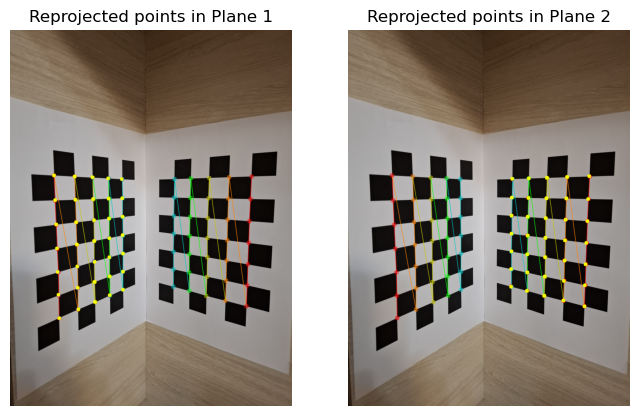

In [15]:
vis1 = img.copy()
plane_id = 0

proj_points, _ = cv2.projectPoints(objpoints[plane_id], rvecs[plane_id], tvecs[plane_id], K, dist)

for i in range(0, len(proj_points)):
    p_orig = tuple(imgpoints[plane_id][i][0].astype(int))
    p_proj = tuple(proj_points[i][0].astype(int))

    cv2.circle(vis1, p_orig, 5, (255, 0, 0), -1) #original (red)
    cv2.circle(vis1, p_proj, 5, (0, 255, 255), -1) #projected (yellow)
    cv2.line(vis1, p_orig, p_proj, (255, 255, 0), 1)



vis2 = img.copy()
plane_id = 1

proj_points, _ = cv2.projectPoints(objpoints[plane_id], rvecs[plane_id], tvecs[plane_id], K, dist)

for i in range(0, len(proj_points)):
    p_orig = tuple(imgpoints[plane_id][i][0].astype(int))
    p_proj = tuple(proj_points[i][0].astype(int))

    cv2.circle(vis2, p_orig, 5, (0, 0, 255), -1) #original (red)
    cv2.circle(vis2, p_proj, 5, (0, 255, 255), -1) #projected (yellow)
    cv2.line(vis2, p_orig, p_proj, (0, 255, 0), 1)




plt.figure(figsize=(8,16))
plt.subplot(1,2,1)
plt.title('Reprojected points in Plane 1')
plt.imshow(cv2.cvtColor(vis1, cv2.COLOR_BGR2RGB))
plt.axis('off')

plt.subplot(1,2,2)
plt.title('Reprojected points in Plane 2')
plt.imshow(cv2.cvtColor(vis2, cv2.COLOR_BGR2RGB))
plt.axis('off')
